# Plotting The Data Of A "Hits" Tree

**Version**: 1

**Last modified**: 2026-09-01

**Compatible with opengate-gate-tree version:** 0.5.0

**Author**: Mateusz Jakub Bała

## About

The tutorials draw their plots with one set of helpers, `tools.plotting`, so
that every notebook looks the same and none of them spends ten lines on a
histogram. This notebook is the tour of those helpers, worked on a real
"Hits" tree.

It is about the picture rather than the physics: what to draw a quantity
with, and what changes when the quantity is a discrete identifier rather
than a continuous measurement.

## What will you learn from this notebook

- how to draw the columns of a tree: histograms in one and two dimensions,
  bar charts, pie charts
- how to draw a discrete column so that a bar stands over the value it counts,
  and why the ordinary form misleads there
- how to put several columns on one pair of axes and compare them
- how to say what a plot should look like: colours, transparency, line styles,
  labels

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

The helpers live in `tools/`, beside this notebook, and the style is applied
once so that every plot on the page matches.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-09-01


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

Two paths: the one place this notebook may write, and the example file it
reads. The file is a small GATE output carried in the repository; what it holds
is described in [`../data/README.md`](../data/README.md).

In [2]:
output = paths.output_dir("tutorial-01-tools-plotting")
example_input = paths.input_example("positronium-source-all-variants.root")

Read the tree, keeping the branches this notebook draws, and take the pandas
view of it.

In [3]:
from opengate_gate_tree import GammaType, GateTree, read_tree

hits = read_tree(
    example_input,
    GateTree.HITS,
    [
        "trackID",
        "posX",
        "posY",
        "posZ",
        "edep",
        "decayType",
        "gammaType",
        "decayIndex",
    ],
)
data = hits.to_dataframe()
data

,trackID,posX,posY,posZ,edep,decayType,gammaType,decayIndex
0,2,-184.148819,2.103387,-78.308502,0.094538,1,2,0
1,2,-184.547928,2.548918,-78.674561,0.416461,1,2,0
2,1,186.769531,-2.133321,79.422951,0.220403,1,2,0
3,1,186.650757,-2.092664,80.146744,0.290596,1,2,0
4,2,167.915894,77.666138,88.527336,0.132729,1,2,1
...,...,...,...,...,...,...,...,...
495,1,-93.682663,-149.508942,117.026428,0.033188,0,0,-1
496,1,-93.084274,-149.406082,116.207977,0.225968,0,0,-1
497,3,176.949173,-103.687340,-25.002714,0.505492,1,2,0
498,2,-127.397911,123.540756,92.852348,0.099978,1,2,0


`describe()` is the quickest way to see which columns hold a handful of whole
numbers and which hold a measurement — that difference decides how each one is
drawn.

In [4]:
data.describe()

,trackID,posX,posY,posZ,edep,decayType,gammaType,decayIndex
count,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000
mean,1.84400,2.734614,0.386264,2.786574,0.312618,1.238000,1.90000,-0.024000
std,0.88387,117.521179,119.851616,122.002853,0.227057,0.652846,0.78946,0.468896
min,1.00000,-209.137985,-205.190277,-212.612015,0.000397,0.000000,0.00000,-1.000000
25%,1.00000,-91.308346,-103.634068,-105.064615,0.155917,1.000000,2.00000,0.000000
50%,2.00000,2.922194,-1.987431,3.463646,0.277730,1.000000,2.00000,0.000000
75%,2.00000,102.122906,107.593241,112.184303,0.437749,2.000000,2.00000,0.000000
max,4.00000,211.464859,218.725311,228.753265,1.300000,2.000000,3.00000,1.000000


### Discrete Columns

`trackID`, `decayType`, `gammaType` and `decayIndex` hold identifiers and small
counts. Each of them can be shown as:

- a histogram in one dimension,
- a bar chart,
- a pie chart,

and two of them together as a two-dimensional histogram or as bars standing
side by side. Each one below, in turn.

#### A Histogram In One Dimension

`trackID` takes the values 1, 2, 3 and 4, and the question is how often each
occurs. Drawn the ordinary way, with a range and a number of bins:

<Axes: xlabel='trackID', ylabel='counts'>

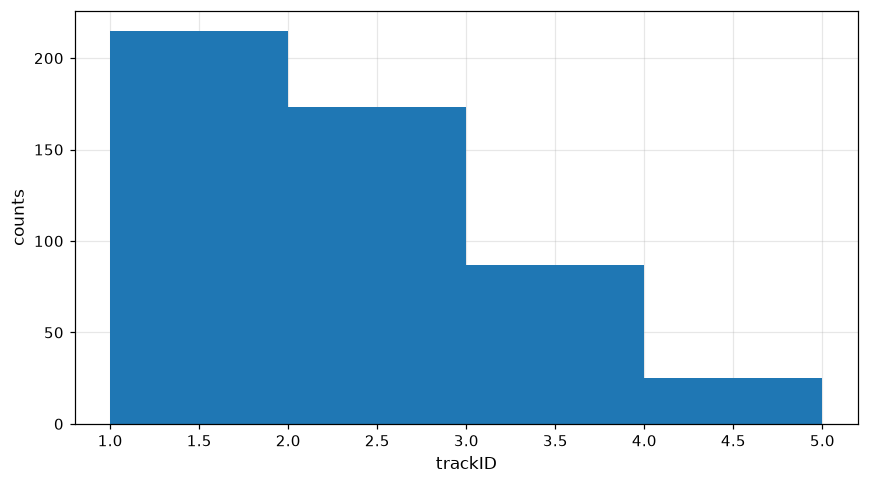

In [5]:
plotting.plot_hist_1d(
    data["trackID"],
    xrange=(1, 5),
    xbins=4,
    xtitle="trackID",
)

The picture answers, but it reads badly: the bar for track 1 runs from 1 to 2,
so it looks as though it belonged to both. That is what bins are for — ranges,
not values.

`discrete=True` counts each value on its own and centres its bar over it:

<Axes: xlabel='trackID', ylabel='counts'>

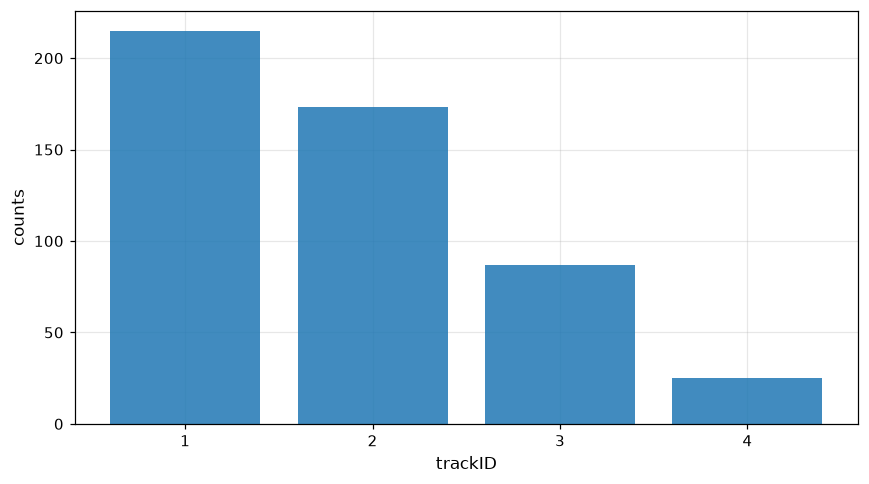

In [6]:
plotting.plot_hist_1d(
    data["trackID"],
    xtitle="trackID",
    discrete=True,
)

Now each bar stands over the value it counts, and the axis is ticked at the
values themselves. `xrange` and `xbins` are not passed: there are no bins to
place, so they would be ignored.

#### A Bar Chart

`decayType` takes the values 0, 1 and 2. A bar chart draws heights that were
computed elsewhere, which is what to reach for when the heights are counts of
values **that were expected**, including ones the file happens not to hold.

<Axes: xlabel='decayType', ylabel='counts'>

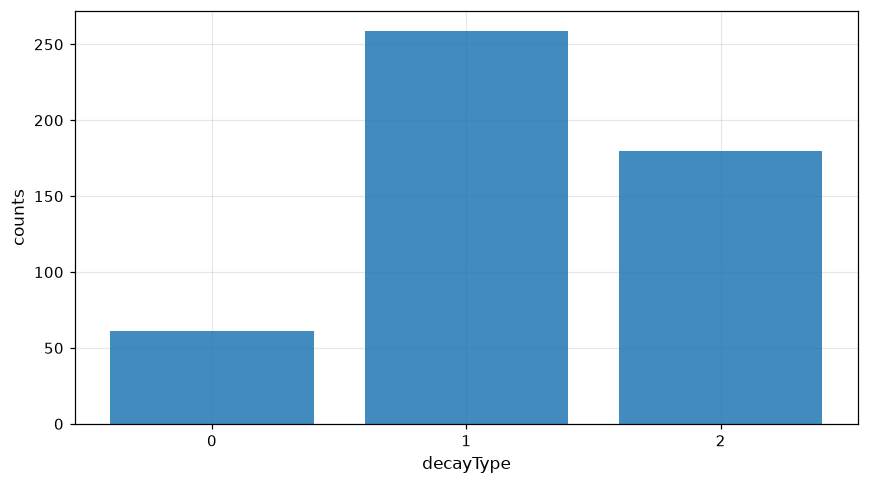

In [7]:
decay_types = data["decayType"]
decay_type_expected_values = [0, 1, 2]

plotting.plot_bar(
    decay_type_expected_values,
    heights=[decay_types[decay_types == dt].shape[0] for dt in decay_type_expected_values],
    xtitle="decayType",
)

Counting by hand is what makes the expected values visible: a value nobody
observed still gets its place on the axis. When only the observed values
matter, `plotting.count_values(column)` returns them with their counts in one
call.

#### A Pie Chart

`gammaType` says what each gamma was. A pie chart is the form to reach for when
the question is what share of the whole each kind takes.

<Axes: title={'center': 'Types of detected gamma'}>

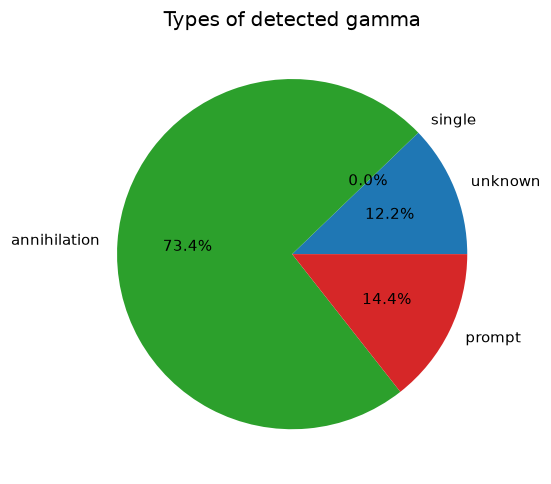

In [8]:
gamma_types = data["gammaType"]
gamma_type_expected_values = [0, 1, 2, 3]
counts_per_type = [gamma_types[gamma_types == gt].shape[0] for gt in gamma_type_expected_values]

plotting.plot_pie_chart(
    counts_per_type,
    labels=["unknown", "single", "annihilation", "prompt"],
    title="Types of detected gamma",
)

Two of the four kinds say something about the simulation that produced this
file.

There are no **single** gammas, which is expected: no single-gamma source took
part in it.

The **unknown** ones are gammas written by a source other than a
`PositroniumSource` — here a back-to-back source, which the simulation used
alongside one, so the file holds annihilation and prompt gammas from the
positronium source and unknown ones from the other. What each value means is
in [PositroniumSource
Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html).

#### A Histogram In Two Dimensions

Which `trackID` was given to which kind of gamma? Both columns are discrete, so
both axes are counted value by value:

<Axes: xlabel='trackID', ylabel='gammaType'>

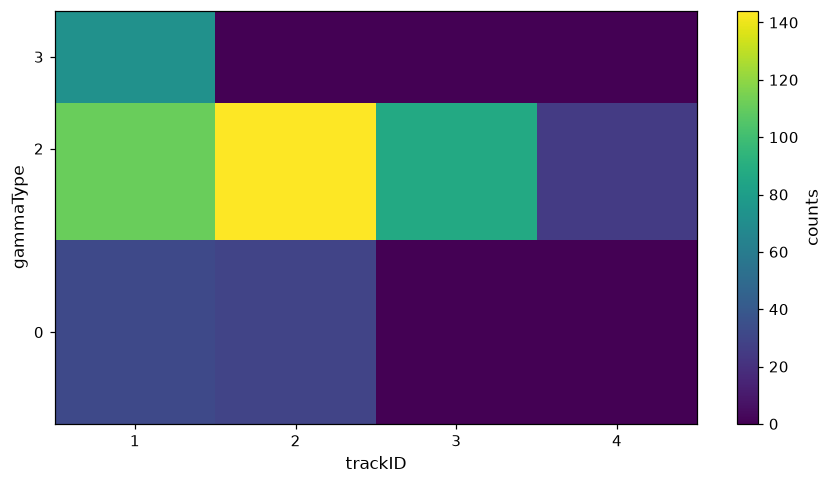

In [9]:
plotting.plot_hist_2d(
    data["trackID"],
    data["gammaType"],
    xtitle="trackID",
    ytitle="gammaType",
    discrete=True,
)

Each cell is centred on its pair of values, and both axes are ticked at the
values. `discrete` also takes a pair of booleans, for one discrete axis against
a continuous one — `discrete=(True, False)`.

#### Bars Standing Side By Side

In which range of deposited energy does each kind of gamma turn up most often?
The energies are split into three ranges. `edep` is in MeV, as GATE writes it,
so the boundaries are 0.2 and 0.4 MeV — 200 and 400 keV.

In [10]:
edep = data["edep"]

category_masks = {
    "(0, 200) keV": edep < 0.2,
    "[200, 400) keV": (edep >= 0.2) & (edep < 0.4),
    "[400, 600) keV": (edep >= 0.4) & (edep < 0.6),
}

The gammas of each range, and how many of them there are. Note that each mask
is used on the column it was built from — a mask of one selection applied to
another is aligned by pandas on the index, silently, and answers something
nobody asked.

In [11]:
gamma_types_by_category = {label: gamma_types[mask] for label, mask in category_masks.items()}

{label: values.shape[0] for label, values in gamma_types_by_category.items()}

{'(0, 200) keV': 174, '[200, 400) keV': 177, '[400, 600) keV': 122}

One row of bars per range, each row counted over the same expected values, and
each row drawn in its own colour:

<Axes: xlabel='gammaType', ylabel='counts'>

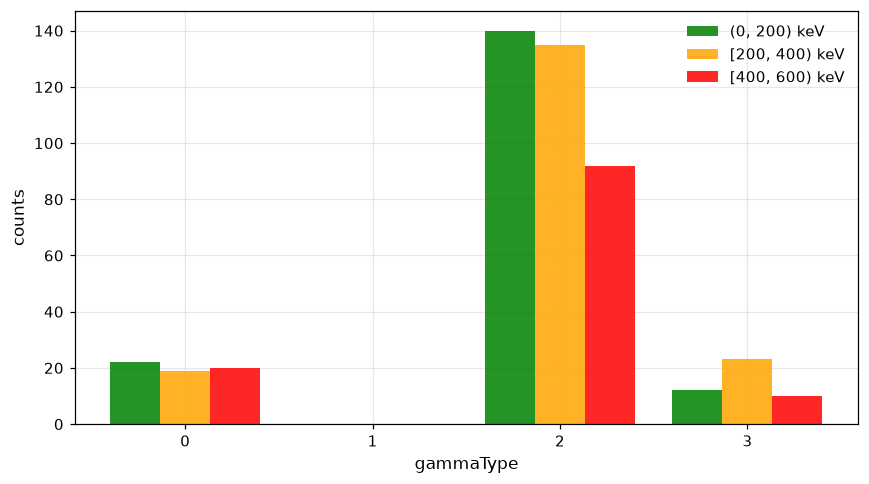

In [12]:
gamma_type_to_check = [0, 1, 2, 3]
colors = ["green", "orange", "red"]

bars = [
    plotting.BarParams(
        x=gamma_type_to_check,
        heights=[values[values == gt].shape[0] for gt in gamma_type_to_check],
        label=label,
        color=color,
    )
    for (label, values), color in zip(gamma_types_by_category.items(), colors, strict=True)
]

plotting.plot_bars(bars, xtitle="gammaType", ytitle="counts")

The three bars above one value are what makes the comparison: annihilation
gammas dominate every range, prompt gammas are most frequent in the middle one,
and the value 1 is empty everywhere, since no single gammas were emitted.

### Continuous Columns

The measurements in this tree are the deposited energy `edep` and the position
of a hit, `posX`, `posY` and `posZ`. For those, bins are the right form:

- a histogram in one dimension,
- several histograms over one binning,
- a histogram in two dimensions.

#### A Histogram In One Dimension

Where along the axis of the detector did the hits happen? The range is 460 mm
wide over 100 bins, so a bin is 4.6 mm — worth saying on the axis, because a
count means nothing without the width it was counted over.

<Axes: title={'center': 'Where the hits happened along z'}, xlabel='z [mm]', ylabel='counts / 4.6 mm'>

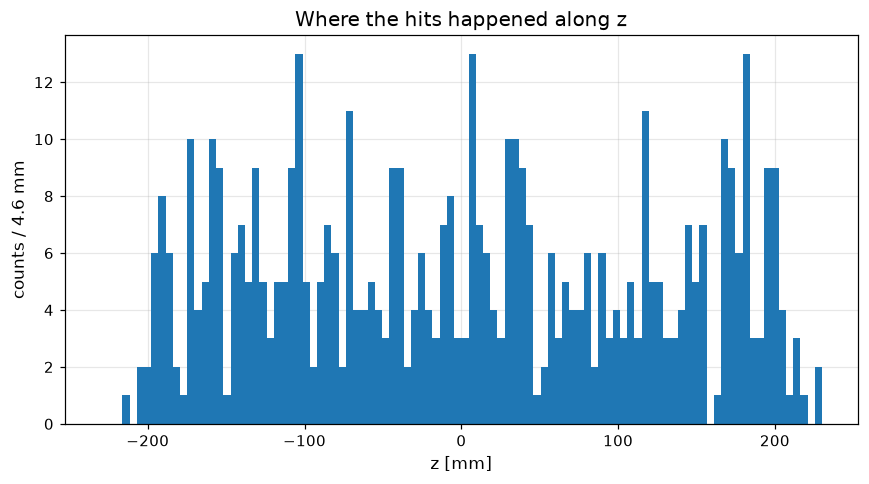

In [13]:
plotting.plot_hist_1d(
    data["posZ"],
    xrange=(-230, 230),
    xbins=100,
    xtitle="z [mm]",
    ytitle="counts / 4.6 mm",
    title="Where the hits happened along z",
)

#### Several Histograms Over One Binning

The energy deposited by annihilation gammas against the energy deposited by
prompt ones. The kinds are named by their enum members rather than by the
numbers behind them: `GammaType.ANNIHILATION` is the integer GATE wrote, so the
comparison runs on the column as it was read.

<Axes: title={'center': 'What each kind of gamma left behind'}, xlabel='energy deposited [MeV]', ylabel='counts / 20 keV'>

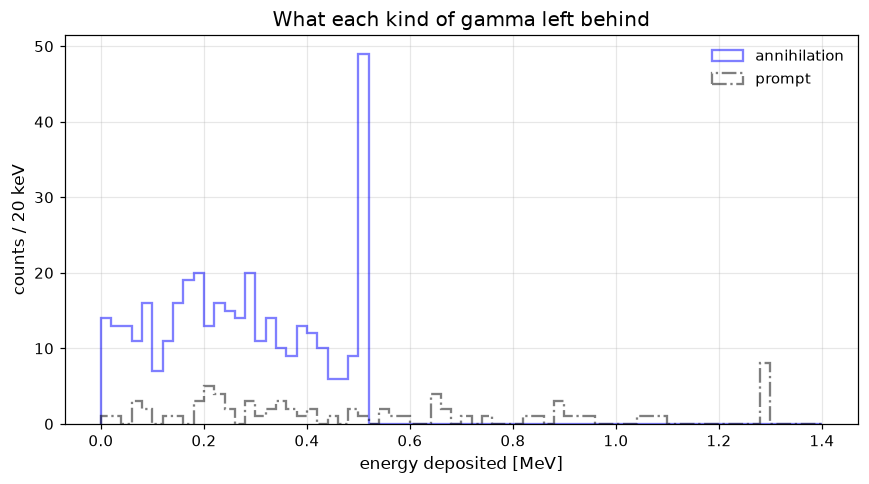

In [14]:
edep_annihilation = edep[gamma_types == GammaType.ANNIHILATION]
edep_prompt = edep[gamma_types == GammaType.PROMPT]

annihilation = plotting.HistogramParams(
    edep_annihilation,
    label="annihilation",
    color="blue",
    linestyle="-",
    fill=False,
)
prompt = plotting.HistogramParams(
    edep_prompt,
    label="prompt",
    color="black",
    linestyle="-.",
    fill=False,
)

plotting.plot_hists_1d(
    histograms=[annihilation, prompt],
    xrange=(0.0, 1.4),
    xbins=70,
    xtitle="energy deposited [MeV]",
    ytitle="counts / 20 keV",
    title="What each kind of gamma left behind",
)

Both histograms are binned the same way, which is what makes them comparable —
`plot_hists_1d` takes one binning for all of them, from `xrange` and `xbins` or,
when no range is given, from every series together. The annihilation gammas
stop at 511 keV, which is all they have; the prompt ones reach beyond it.

#### A Histogram In Two Dimensions

Where the hits happened in the x-y plane, seen from along the axis:

<Axes: title={'center': 'Hit positions in the x-y plane'}, xlabel='x [mm]', ylabel='y [mm]'>

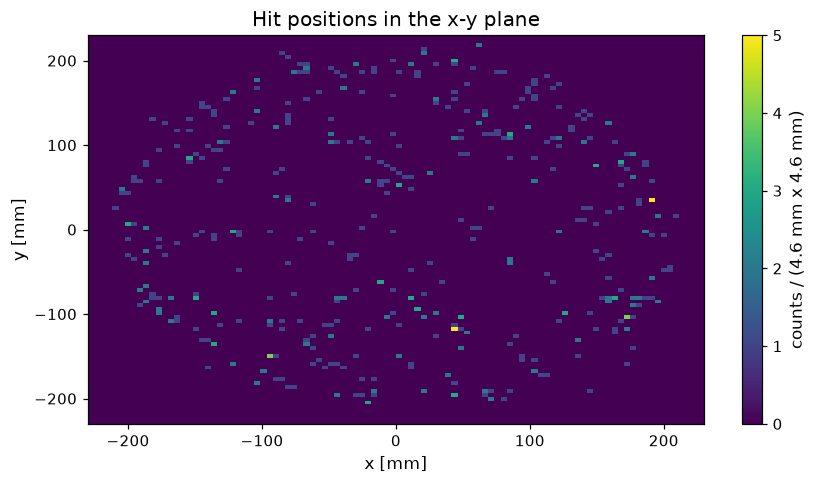

In [15]:
plotting.plot_hist_2d(
    x=data["posX"],
    y=data["posY"],
    xrange=(-230, 230),
    xbins=100,
    yrange=(-230, 230),
    ybins=100,
    xtitle="x [mm]",
    ytitle="y [mm]",
    title="Hit positions in the x-y plane",
    colorbar=True,
    colorbar_title="counts / (4.6 mm x 4.6 mm)",
)

The detector of this scene is a spherical shell, 200 mm across on the inside,
and what the picture shows is that shell seen from along the axis: a disc that
is brightest at the rim, because a line of sight near the edge passes through
more of the shell than one through the middle. Two hundred and thirty-four of the five
hundred hits fall in the outer quarter of the projected radius.

## Summary

Every column of a "Hits" tree has a form that shows it honestly: bins for a
measurement, one bar per value for an identifier, and one binning shared by
histograms that are meant to be compared. `tools.plotting` draws all of them,
and takes the colours, the line styles and the labels from `HistogramParams`,
`GraphParams` and `BarParams`.

## Bibliography

- [Data representations](https://opengate-gate-tree.readthedocs.io/en/latest/guide/representations.html)
  — the pandas view of a tree, which every plot here is drawn from
- [PositroniumSource Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html)
  — what the values of `gammaType` and `decayType` mean
- [The "Hits" Tree](https://opengate-gate-tree.readthedocs.io/en/latest/guide/hits.html)
  — the branches this notebook reads
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — why `edep` is in MeV and `posZ` in mm
- [`tools/README.md`](tools/README.md) — every plotting helper used here

## Changelog

- v1: written.